> https://www.kaggle.com/code/mahmudulhasanshauqi/perceptron

In [1]:
import numpy as np
import pandas as pd
import os
import math

In [93]:
class Perceptron(object):
    def __init__(self,learning_rate=0.01, n_iters=100,random_state=1):
        self.lr = learning_rate
        self.n_iters = n_iters
        self.random_state = random_state
        self.w = None
        self.b = None
        self.up_num=None
    
    def fit(self,X:np.array,y:np.array):
        random_gen = np.random.RandomState(self.random_state)
        self.w = random_gen.normal(0,0.1,X.shape[1])
        self.b = 0.0
        
        self.up_num = []
        for _ in range(self.n_iters):
            up_num = 0
            for x,target in zip(X,y):
                update = self.lr * (target-self.predit(x))
                if update!=0.0:
                    self.w += np.dot(x,update)
                    self.b += update
                    up_num+=1
            self.up_num.append(up_num)
    def predit(self,x:np.array):
        p = np.dot(x,self.w)+self.b
        return np.where(p>=0,1,-1)
    

In [94]:
df = pd.read_csv('./input/iris.data.csv')
X = df.iloc[0:100,[0,2]].values
y = df.iloc[0:100, 4].values
y = np.where(y == 'Iris-setosa', -1, 1)

In [95]:
net = Perceptron(learning_rate=0.1)
net.fit(X,y)

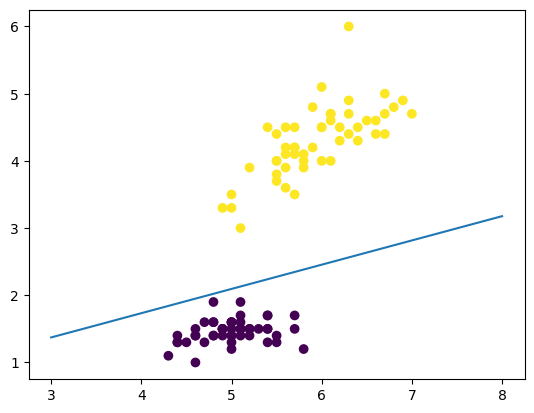

In [96]:
import matplotlib.pyplot as plt
x = np.linspace(3,8,100)
plt.scatter(X[:,0],X[:,1],c=y)
plt.plot(x,(-net.b-net.w[0]*x)/net.w[1])
plt.show()

In [97]:
net.predit(X)

array([-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1])

In [98]:
print(net.up_num)

[2, 2, 3, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


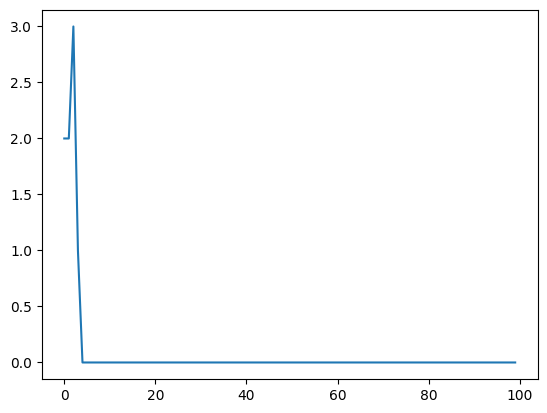

In [99]:
x = [x for x in range(len(net.up_num))]
plt.plot(x,net.up_num)
plt.show()